# import

In [4]:
import h5py
import numpy as np

file_path = '/Users/kyu/Downloads/broadband_data_20260411_143606.h5'

with h5py.File(file_path, "r") as f:
    raw = f["acquisition/ElectricalSeries"][:]
    t_ns = f["acquisition/timestamp_ns"][:]  # optional, can ignore

n_time = len(t_ns)
n_ch = len(raw) // n_time

data = raw.reshape(n_time, n_ch)   # no timestamp here

X_signal = data[:, :-12]
X_aux = data[:, -12:]

fs = 31_000

print("signal shape:", X_signal.shape)
print("aux shape:", X_aux.shape)

signal shape: (13183488, 64)
aux shape: (13183488, 12)


In [7]:
import numpy as np
from importlib import reload
import kyunghwan_spike_functions as s
reload(s)


fs_raw = 31_000
fs_rate = 1000

n_time, n_ch = X_signal.shape
n_time_rate = int(np.floor(n_time * fs_rate / fs_raw))

rate_mat = np.zeros((n_time_rate, n_ch))

for ch in range(n_ch):
    res = s.threshold_and_rate(
        X_signal[:, ch],
        fs_raw=fs_raw,
        fs_rate=fs_rate,
        k=5,
        mode="negative",
        refractory_s=0.001,
        smooth_method="none",
        smooth_sigma_s=0.01   # 10 ms smoothing on 1 kHz timeline
    )
    rate_mat[:, ch] = res["rate"]

print(rate_mat.shape)

(425273, 64)


In [8]:
buttons_raw = X_aux[:, 4:]       # shape: (time_raw, 8)
buttons_ds  = X_aux[:, 4:]    # optional, for plotting / alignment later

print("buttons_raw shape:", buttons_raw.shape)
print("buttons_ds shape:", buttons_ds.shape)

def find_button_events_ds(button_data, threshold=None):
    """
    button_data: (time, n_buttons)

    Returns:
        events[ch] = {
            "onsets":  array of onset indices,
            "offsets": array of offset indices,
            "active":  boolean active trace
        }

    If threshold is None, a per-channel threshold is chosen automatically.
    """
    n_time, n_buttons = button_data.shape
    events = {}

    for ch in range(n_buttons):
        x = button_data[:, ch]

        # automatic threshold
        if threshold is None:
            thr = 0.5 * np.max(np.abs(x))
        else:
            thr = threshold

        active = np.abs(x) > thr
        d = np.diff(active.astype(int))

        onsets = np.where(d == 1)[0] + 1
        offsets = np.where(d == -1)[0] + 1

        # handle edge cases
        if active[0]:
            onsets = np.r_[0, onsets]
        if active[-1]:
            offsets = np.r_[offsets, n_time]

        events[ch] = {
            "onsets": onsets,
            "offsets": offsets,
            "active": active,
            "threshold": thr
        }

    return events

events_ds = find_button_events_ds(buttons_ds, threshold=None)

for ch in range(buttons_ds.shape[1]):
    print(
        f"Button {ch}: {len(events_ds[ch]['onsets'])} presses, "
        f"threshold={events_ds[ch]['threshold']:.4f}"
    )

buttons_raw shape: (13183488, 8)
buttons_ds shape: (13183488, 8)
Button 0: 14 presses, threshold=16383.5000
Button 1: 11 presses, threshold=16383.5000
Button 2: 15 presses, threshold=16383.5000
Button 3: 16 presses, threshold=16383.5000
Button 4: 7 presses, threshold=16383.5000
Button 5: 6 presses, threshold=16383.5000
Button 6: 0 presses, threshold=0.0000
Button 7: 0 presses, threshold=0.0000


In [9]:
def extract_event_windows_ds(X, onset_indices, fs, t_pre=0.5, t_post=0.5):
    """
    X: (time, channels)
    onset_indices: onset sample indices
    fs: sampling rate

    Returns:
        windows:    (n_events, win_len, channels)
        kept_onsets
        rel_t:      relative time vector
    """
    n_pre = int(round(t_pre * fs))
    n_post = int(round(t_post * fs))
    win_len = n_pre + n_post

    windows = []
    kept_onsets = []

    for onset in onset_indices:
        start = onset - n_pre
        end = onset + n_post

        if start < 0 or end > X.shape[0]:
            continue

        windows.append(X[start:end, :])
        kept_onsets.append(onset)

    if len(windows) == 0:
        windows = np.empty((0, win_len, X.shape[1]))
        kept_onsets = np.array([], dtype=int)
    else:
        windows = np.stack(windows, axis=0)
        kept_onsets = np.array(kept_onsets, dtype=int)

    rel_t = np.arange(-n_pre, n_post) / fs
    return windows, kept_onsets, rel_t

In [10]:
from scipy.signal import butter, sosfilt

fs_raw = 31000
fs_rate = 1000
down = fs_raw // fs_rate   # 31

# lowpass before decimation (avoid aliasing)
sos = butter(6, 100, btype="low", fs=fs_raw, output="sos")

X_aux_filt = sosfilt(sos, X_aux, axis=0)
X_aux_ds = X_aux_filt[::down]

print("X_aux_1k shape:", X_aux_ds.shape)

X_aux_1k shape: (425274, 12)


In [11]:
# 1. build 1 kHz aux
X_aux_filt = sosfilt(sos, X_aux, axis=0)
X_aux_ds = X_aux_filt[::down]

# 2. align with rate_mat
n_shared = min(rate_mat.shape[0], X_aux_ds.shape[0])
rate_mat = rate_mat[:n_shared]
X_aux_ds = X_aux_ds[:n_shared]

# 3. extract buttons from 1 kHz aux
buttons_ds = X_aux_ds[:, 4:]

print("buttons_ds shape:", buttons_ds.shape)

buttons_ds shape: (425273, 8)


In [17]:
from scipy.signal import butter, sosfilt
import numpy as np

# -----------------------------
# 1) downsample aux to 1 kHz
# -----------------------------
fs_raw = 31000
fs_rate = 100
down = fs_raw // fs_rate

sos = butter(6, 100, btype="low", fs=fs_raw, output="sos")
X_aux_filt = sosfilt(sos, X_aux, axis=0)
X_aux_ds = X_aux_filt[::down]

# -----------------------------
# 2) align exactly to rate_mat
# -----------------------------
n_shared = min(rate_mat.shape[0], X_aux_ds.shape[0])
rate_mat = rate_mat[:n_shared]
X_aux_ds = X_aux_ds[:n_shared]

# -----------------------------
# 3) rebuild buttons from THIS aux
# -----------------------------
buttons_ds = X_aux_ds[:, 4:]

print("rate_mat shape:", rate_mat.shape)
print("X_aux_ds shape:", X_aux_ds.shape)
print("buttons_ds shape:", buttons_ds.shape)

# -----------------------------
# 4) REDEFINE event detector here
# -----------------------------
def find_button_events_ds(button_data, threshold=None):
    n_time, n_buttons = button_data.shape
    events = {}

    for ch in range(n_buttons):
        x = np.asarray(button_data[:, ch], dtype=float)

        if threshold is None:
            thr = 0.5 * np.max(np.abs(x))
        else:
            thr = float(threshold)

        active = np.abs(x) > thr
        d = np.diff(active.astype(int))

        onsets = np.where(d == 1)[0] + 1
        offsets = np.where(d == -1)[0] + 1

        if active[0]:
            onsets = np.r_[0, onsets]
        if active[-1]:
            offsets = np.r_[offsets, n_time]

        events[ch] = {
            "onsets": onsets,
            "offsets": offsets,
            "active": active,
            "threshold": thr
        }

    return events

# -----------------------------
# 5) rebuild events RIGHT NOW
# -----------------------------
events_ds = find_button_events_ds(buttons_ds, threshold=None)

for ch in range(buttons_ds.shape[1]):
    onsets = events_ds[ch]["onsets"]
    print(f"button {ch}: n_onsets={len(onsets)}")
    if len(onsets) > 0:
        print("  first few onsets:", onsets[:10])
        print("  min/max:", onsets.min(), onsets.max())
        print("  all onsets valid:", np.all(onsets < buttons_ds.shape[0]))

rate_mat shape: (42528, 64)
X_aux_ds shape: (42528, 12)
buttons_ds shape: (42528, 8)
button 0: n_onsets=14
  first few onsets: [ 1344  2321  2591  3299 12090 15977 17787 20957 22341 22878]
  min/max: 1344 38844
  all onsets valid: True
button 1: n_onsets=11
  first few onsets: [ 1474  7174  8059 11251 19480 21321 23399 26712 35221 37090]
  min/max: 1474 41173
  all onsets valid: True
button 2: n_onsets=15
  first few onsets: [ 1585  2222  5482  5770  8587  9916 15165 16510 17137 17276]
  min/max: 1585 35868
  all onsets valid: True
button 3: n_onsets=16
  first few onsets: [ 1713  3426  6888  7622  9089 13582 18692 23744 26865 27973]
  min/max: 1713 41683
  all onsets valid: True
button 4: n_onsets=7
  first few onsets: [ 1845  2718 12243 15306 17428 24368 39633]
  min/max: 1845 39633
  all onsets valid: True
button 5: n_onsets=6
  first few onsets: [11792 17630 18127 31517 31675 33378]
  min/max: 11792 33378
  all onsets valid: True
button 6: n_onsets=0
button 7: n_onsets=0


In [19]:
t_pre = .1
t_post = 0.1
fs_rate = 100

# buttons_ds should already be the 1 kHz button channels
# example:
# buttons_ds = X_aux_1k[:, 4:]

button_windows_rate = {}
button_windows_aux = {}

for ch in range(buttons_ds.shape[1]):
    onsets = events_ds[ch]["onsets"]   # these must be on the 1 kHz timeline

    rate_wins, kept_onsets, rel_t = extract_event_windows_ds(
        rate_mat,
        onsets,
        fs=fs_rate,
        t_pre=t_pre,
        t_post=t_post
    )

    aux_wins, _, _ = extract_event_windows_ds(
        X_aux_ds,   # or X_aux_1k, whichever is your 1 kHz aux array
        onsets,
        fs=fs_rate,
        t_pre=t_pre,
        t_post=t_post
    )

    button_windows_rate[ch] = {
        "windows": rate_wins,   # (n_events, win_len, n_rate_channels)
        "onsets": kept_onsets,
        "rel_t": rel_t
    }

    button_windows_aux[ch] = {
        "windows": aux_wins,    # (n_events, win_len, 12) on 1 kHz timeline
        "onsets": kept_onsets,
        "rel_t": rel_t
    }

    print(f"Button {ch}: rate windows shape = {rate_wins.shape}")

Button 0: rate windows shape = (14, 20, 64)
Button 1: rate windows shape = (11, 20, 64)
Button 2: rate windows shape = (15, 20, 64)
Button 3: rate windows shape = (16, 20, 64)
Button 4: rate windows shape = (7, 20, 64)
Button 5: rate windows shape = (6, 20, 64)
Button 6: rate windows shape = (0, 20, 64)
Button 7: rate windows shape = (0, 20, 64)


using buttons: [0, 1, 2, 3, 4, 5]
delta_mat shape: (6, 64)
abs_delta_mat shape: (6, 64)
z_delta_mat shape: (6, 64)

TOP BUTTON-CHANNEL PAIRS BY CHANGE
 1. button 5, channel 55 | delta=66.6667, abs_delta=66.6667, z_delta=1.6330
 2. button 1, channel 39 | delta=45.4545, abs_delta=45.4545, z_delta=1.5076
 3. button 3, channel 12 | delta=37.5000, abs_delta=37.5000, z_delta=1.5000
 4. button 4, channel 23 | delta=42.8571, abs_delta=42.8571, z_delta=1.1339
 5. button 3, channel 7 | delta=25.0000, abs_delta=25.0000, z_delta=1.0000
 6. button 3, channel 33 | delta=43.7500, abs_delta=43.7500, z_delta=0.9783
 7. button 3, channel 28 | delta=31.2500, abs_delta=31.2500, z_delta=0.9149
 8. button 5, channel 58 | delta=-50.0000, abs_delta=50.0000, z_delta=-0.9129
 9. button 5, channel 1 | delta=-50.0000, abs_delta=50.0000, z_delta=-0.9129
10. button 1, channel 43 | delta=27.2727, abs_delta=27.2727, z_delta=0.9045
11. button 1, channel 52 | delta=27.2727, abs_delta=27.2727, z_delta=0.9045
12. button 

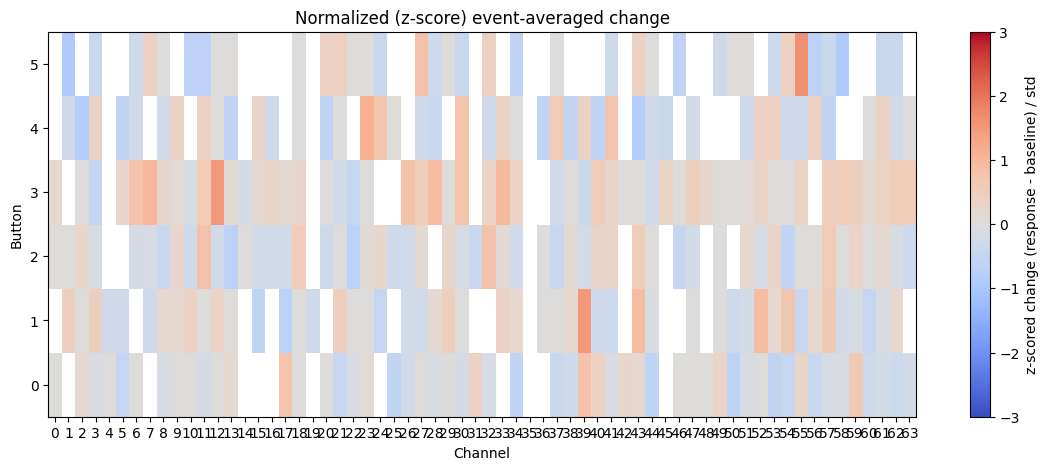

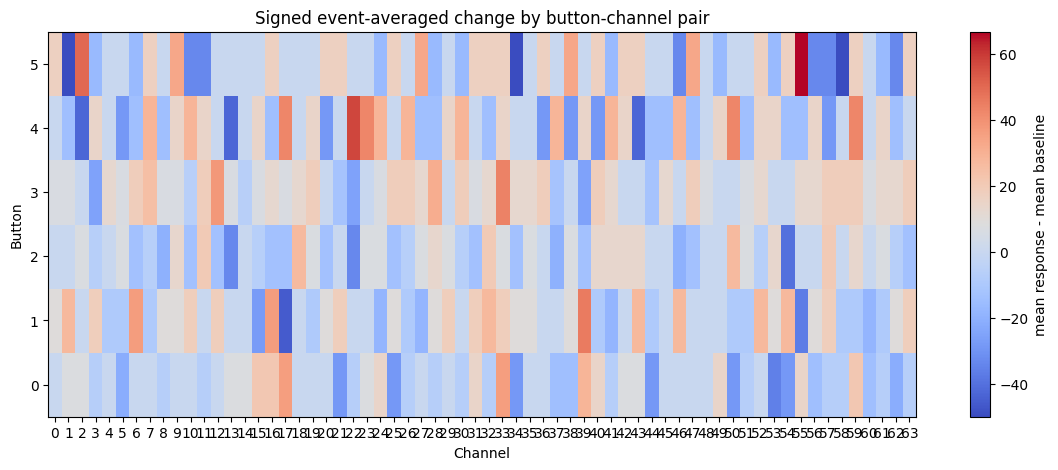

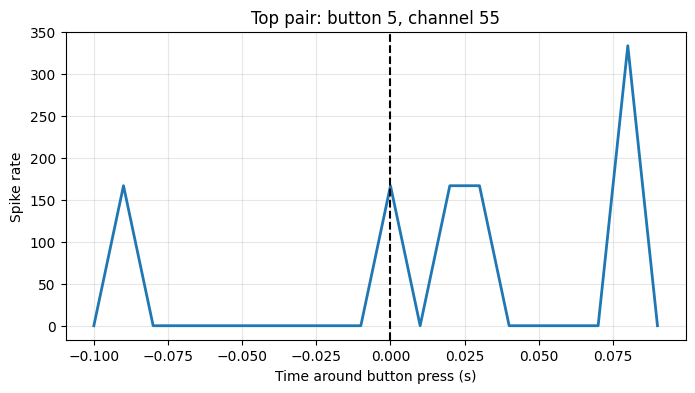

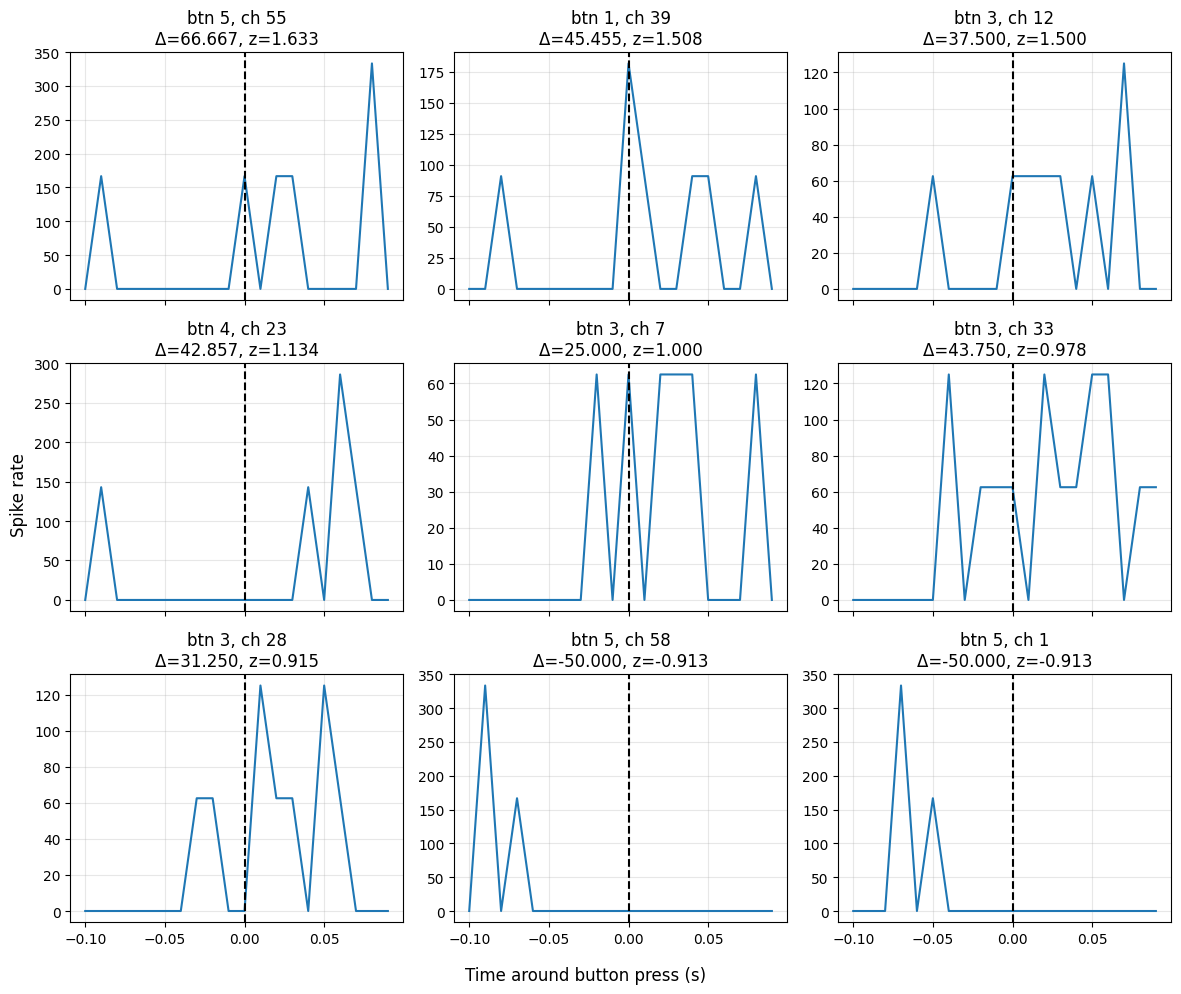

In [20]:
import matplotlib.pyplot as plt
valid_buttons = [0, 1, 2, 3, 4, 5]

# optional safety check
valid_buttons = [
    b for b in valid_buttons
    if b in button_windows_rate and button_windows_rate[b]["windows"].shape[0] > 0
]

print("using buttons:", valid_buttons)

# --------------------------------------------------
# SETTINGS
# --------------------------------------------------
baseline_win = (-0.1, 0.0)
response_win = (0.0, 0.1)

n_channels = rate_mat.shape[1]

# outputs
delta_mat = []
abs_delta_mat = []
z_delta_mat = []
eta_by_button_valid = {}

# --------------------------------------------------
# COMPUTE EVENT-AVERAGED ACTIVITY + CHANGE METRICS
# --------------------------------------------------
for button in valid_buttons:
    wins = button_windows_rate[button]["windows"]   # (n_events, win_len, n_channels)
    rel_t = button_windows_rate[button]["rel_t"]    # (win_len,)

    eta = wins.mean(axis=0)   # (win_len, n_channels)
    eta_by_button_valid[button] = eta

    baseline_mask = (rel_t >= baseline_win[0]) & (rel_t < baseline_win[1])
    response_mask = (rel_t >= response_win[0]) & (rel_t < response_win[1])

    baseline_vals = wins[:, baseline_mask, :].mean(axis=1)   # (n_events, n_channels)
    response_vals = wins[:, response_mask, :].mean(axis=1)   # (n_events, n_channels)

    delta = response_vals.mean(axis=0) - baseline_vals.mean(axis=0)
    abs_delta = np.abs(delta)

    baseline_std = baseline_vals.std(axis=0, ddof=1)
    baseline_std[baseline_std == 0] = np.nan
    z_delta = delta / baseline_std

    delta_mat.append(delta)
    abs_delta_mat.append(abs_delta)
    z_delta_mat.append(z_delta)

delta_mat = np.stack(delta_mat, axis=0)         # (n_valid_buttons, n_channels)
abs_delta_mat = np.stack(abs_delta_mat, axis=0)
z_delta_mat = np.stack(z_delta_mat, axis=0)

button_index_map = {i: b for i, b in enumerate(valid_buttons)}

print("delta_mat shape:", delta_mat.shape)
print("abs_delta_mat shape:", abs_delta_mat.shape)
print("z_delta_mat shape:", z_delta_mat.shape)

# --------------------------------------------------
# RANK BUTTON-CHANNEL PAIRS BY BIGGEST CHANGE
# --------------------------------------------------
score_mat = np.abs(z_delta_mat)

valid_mask = np.isfinite(score_mat)
valid_indices = np.where(valid_mask.ravel())[0]
sorted_valid = valid_indices[np.argsort(score_mat.ravel()[valid_indices])[::-1]]

top_k = min(20, len(sorted_valid))
top_pairs = []

for idx in sorted_valid[:top_k]:
    b_idx, ch = np.unravel_index(idx, score_mat.shape)
    original_button = button_index_map[b_idx]

    top_pairs.append({
        "button": int(original_button),
        "channel": int(ch),
        "delta": float(delta_mat[b_idx, ch]),
        "abs_delta": float(abs_delta_mat[b_idx, ch]),
        "z_delta": float(z_delta_mat[b_idx, ch]) if np.isfinite(z_delta_mat[b_idx, ch]) else np.nan
    })

print("\nTOP BUTTON-CHANNEL PAIRS BY CHANGE")
for i, item in enumerate(top_pairs, 1):
    print(
        f"{i:2d}. button {item['button']}, channel {item['channel']} | "
        f"delta={item['delta']:.4f}, abs_delta={item['abs_delta']:.4f}, z_delta={item['z_delta']:.4f}"
    )

# --------------------------------------------------
# HEATMAP OF CHANGE MAGNITUDE
# --------------------------------------------------
plt.figure(figsize=(14, 5))
plt.imshow(z_delta_mat, aspect='auto', origin='lower', cmap='coolwarm', vmin=-3, vmax=3)
plt.colorbar(label='z-scored change (response - baseline) / std')
plt.xticks(np.arange(n_channels))
plt.yticks(np.arange(len(valid_buttons)), valid_buttons)
plt.xlabel('Channel')
plt.ylabel('Button')
plt.title('Normalized (z-score) event-averaged change')
plt.show()

# --------------------------------------------------
# HEATMAP OF SIGNED CHANGE
# --------------------------------------------------
plt.figure(figsize=(14, 5))
plt.imshow(delta_mat, aspect='auto', origin='lower', cmap='coolwarm')
plt.colorbar(label='mean response - mean baseline')
plt.xticks(np.arange(n_channels))
plt.yticks(np.arange(len(valid_buttons)), valid_buttons)
plt.xlabel('Channel')
plt.ylabel('Button')
plt.title('Signed event-averaged change by button-channel pair')
plt.show()

# --------------------------------------------------
# PLOT TOP PAIR
# --------------------------------------------------
if len(top_pairs) > 0:
    best = top_pairs[0]
    best_button = best["button"]
    best_channel = best["channel"]

    eta = eta_by_button_valid[best_button]
    rel_t = button_windows_rate[best_button]["rel_t"]

    plt.figure(figsize=(8, 4))
    plt.plot(rel_t, eta[:, best_channel], linewidth=2)
    plt.axvline(0, color='k', linestyle='--')
    plt.xlabel("Time around button press (s)")
    plt.ylabel("Spike rate")
    plt.title(f"Top pair: button {best_button}, channel {best_channel}")
    plt.grid(True, alpha=0.3)
    plt.show()

# --------------------------------------------------
# PLOT TOP 9 PAIRS
# --------------------------------------------------
n_plot = min(9, len(top_pairs))
pairs_to_plot = top_pairs[:n_plot]

fig, axes = plt.subplots(3, 3, figsize=(12, 10), sharex=True)
axes = axes.flatten()

for ax, item in zip(axes, pairs_to_plot):
    b = item["button"]
    ch = item["channel"]
    eta = eta_by_button_valid[b]
    rel_t = button_windows_rate[b]["rel_t"]

    ax.plot(rel_t, eta[:, ch])
    ax.axvline(0, color='k', linestyle='--')
    ax.set_title(f"btn {b}, ch {ch}\nΔ={item['delta']:.3f}, z={item['z_delta']:.3f}")
    ax.grid(True, alpha=0.3)

for ax in axes[len(pairs_to_plot):]:
    ax.axis("off")

fig.supxlabel("Time around button press (s)")
fig.supylabel("Spike rate")
plt.tight_layout()
plt.show()

In [21]:
score_mat = np.abs(z_delta_mat)

valid_mask = np.isfinite(score_mat)
valid_indices = np.where(valid_mask.ravel())[0]
sorted_valid = valid_indices[np.argsort(score_mat.ravel()[valid_indices])[::-1]]

top_k = min(20, len(sorted_valid))
top_pairs = []

for idx in sorted_valid[:top_k]:
    b_idx, ch = np.unravel_index(idx, score_mat.shape)
    original_button = button_index_map[b_idx]

    top_pairs.append({
        "button": int(original_button),
        "channel": int(ch),
        "delta": float(delta_mat[b_idx, ch]),
        "abs_delta": float(abs_delta_mat[b_idx, ch]),
        "z_delta": float(z_delta_mat[b_idx, ch])
    })

print("\nTOP BUTTON-CHANNEL PAIRS BY NORMALIZED CHANGE")
for i, item in enumerate(top_pairs, 1):
    print(
        f"{i:2d}. button {item['button']}, channel {item['channel']} | "
        f"z_delta={item['z_delta']:.4f}, delta={item['delta']:.4f}"
    )


TOP BUTTON-CHANNEL PAIRS BY NORMALIZED CHANGE
 1. button 5, channel 55 | z_delta=1.6330, delta=66.6667
 2. button 1, channel 39 | z_delta=1.5076, delta=45.4545
 3. button 3, channel 12 | z_delta=1.5000, delta=37.5000
 4. button 4, channel 23 | z_delta=1.1339, delta=42.8571
 5. button 3, channel 7 | z_delta=1.0000, delta=25.0000
 6. button 3, channel 33 | z_delta=0.9783, delta=43.7500
 7. button 3, channel 28 | z_delta=0.9149, delta=31.2500
 8. button 5, channel 58 | z_delta=-0.9129, delta=-50.0000
 9. button 5, channel 1 | z_delta=-0.9129, delta=-50.0000
10. button 1, channel 43 | z_delta=0.9045, delta=27.2727
11. button 1, channel 52 | z_delta=0.9045, delta=27.2727
12. button 5, channel 27 | z_delta=0.8165, delta=33.3333
13. button 4, channel 43 | z_delta=-0.8018, delta=-42.8571
14. button 4, channel 2 | z_delta=-0.8018, delta=-42.8571
15. button 0, channel 39 | z_delta=0.7868, delta=28.5714
16. button 2, channel 32 | z_delta=0.7746, delta=20.0000
17. button 2, channel 11 | z_delta=0